<a href="https://colab.research.google.com/github/Loading-my-brain/x-band/blob/main/scripts/roads_width_stage1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# X-Band: road location, road width and accuracy (Hinami & Evan)

**What this notebook does.** It takes the team's agreed Kaikōura road lines and prepares them for the routing team in four stages:

| Stage | What it does | Status |
|---|---|---|
| 1 | Load the team's roads and the NZTA road-width reference; first location check | **this version** |
| 2 | Measure road width from the post-quake 1 m lidar using cross-section lines (transects) | next |
| 3 | Accuracy: compare our widths with NZTA widths (MAE/RMSE) and check road positions | later |
| 4 | Export one GeoPackage for routing (parent OSM IDs, width, confidence, passable per vehicle) | later |

**Defaults chosen (change in the config cell if the team agrees something different):**
- Approach: *verify* the existing team roads, not detect new ones from imagery.
- Roads: the team's agreed `kai_route.gpkg` (same commit and checksum as the U-Net notebook), clipped to the shared AOI.
- AOI `173.5, -42.5, 174.0, -42.0`, all maths in NZTM (EPSG:2193, metres).
- Width reference: NZTA *National Road Centreline – RCA data*, `width` field (CC BY 4.0). Remember: it is **current** data (post-rebuild), one typical width per carriageway, not 2016 remaining clearance.

**How to run:** Runtime → Run all, or run each cell top to bottom.

## 1. Install and import

Colab already has most of these. `%pip install` makes sure the few extras exist. Nothing here downloads data yet.

In [ ]:
%pip install -q geopandas rasterio shapely pyproj requests matplotlib

In [ ]:
from pathlib import Path
import hashlib, json, math, time

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests
from shapely.geometry import box, Point, MultiPoint, LineString

print("geopandas", gpd.__version__)

geopandas 1.2.0


## 2. Configuration

Every setting lives here so the rest of the notebook never needs editing.
- **AOI / CRS** match the team's U-Net notebook so our results line up pixel-for-pixel and road-for-road.
- **ROAD_*** pins the exact team road file (a git commit plus a SHA-256 "fingerprint"), so everyone analyses the same roads.
- **NZTA_LAYER_URL** is the public web service behind the NZTA open-data page.

In [ ]:
# ---------------- CONFIG ----------------
AOI_WGS84 = (173.5, -42.5, 174.0, -42.0)   # (min lon, min lat, max lon, max lat) - same as the U-Net notebook
CRS = "EPSG:2193"                           # NZTM: metres, so lengths and widths are real distances

ROOT = Path("/content/xband_roads")
ROOT.mkdir(exist_ok=True)

# Team's agreed road file (identical to the U-Net / RF comparison notebook)
ROAD_COMMIT = "8d739079424b3b6c7077f470346a8840f20a0e1c"
ROAD_SHA256 = "127841d08d83cfc7a3ec82cf34f850d92d6d66550e650cea4304a2a1aff26b0e"
ROAD_URL = ("https://raw.githubusercontent.com/Loading-my-brain/x-band/"
            + ROAD_COMMIT + "/kaikoura_road_route/kai_route.gpkg")

# NZTA National Road Centreline - Road Controlling Authority attributes (point layer 0)
NZTA_LAYER_URL = ("https://services.arcgis.com/CXBb7LAjgIIdcsPt/arcgis/rest/services/"
                  "National_Road_Centreline_Road_Controlling_Authority_data/FeatureServer/0")

# Location check: an NZTA start/end point further than this from any team road is reported as "no match"
MATCH_MAX_M = 100
# ----------------------------------------

aoi_nztm = gpd.GeoSeries([box(*AOI_WGS84)], crs="EPSG:4326").to_crs(CRS).iloc[0]
print("AOI in NZTM (xmin, ymin, xmax, ymax):", [round(v) for v in aoi_nztm.bounds])

AOI in NZTM (xmin, ymin, xmax, ymax): [1641083, 5294222, 1682818, 5350103]


## 3. Load the team's road lines

What happens:
1. Download `kai_route.gpkg` from the team GitHub (only the first time) and check its fingerprint matches.
2. Re-project to NZTM and clip to the AOI.
3. Split multi-part lines into single lines (`explode`) so every row is one continuous road piece.
4. Give each piece an ID. We keep the **parent** OSM IDs (`full_id` / `osm_id`) because that is what routing joins on; our `road_id` is only for our own bookkeeping.

In [ ]:
import pyogrio

road_path = ROOT / "kai_route.gpkg"
if not road_path.exists():
    r = requests.get(ROAD_URL, timeout=120)
    r.raise_for_status()
    road_path.write_bytes(r.content)
assert hashlib.sha256(road_path.read_bytes()).hexdigest() == ROAD_SHA256, \
    "Road file fingerprint does not match the team's agreed version."

layers = pyogrio.list_layers(road_path)
print("Layers in the road file:", [l[0] for l in layers])
roads_raw = gpd.read_file(road_path, layer=layers[0][0])
print("Original CRS:", roads_raw.crs, "| rows:", len(roads_raw))
print("Columns:", list(roads_raw.columns))

roads = roads_raw.to_crs(CRS)
roads = roads[roads.geometry.notna() & ~roads.geometry.is_empty]
roads = gpd.clip(roads, aoi_nztm)                       # keep only the shared AOI
roads = roads.explode(index_parts=False).reset_index(drop=True)
roads = roads[roads.geom_type == "LineString"].reset_index(drop=True)

# Parent ID used by the team handoff (full_id preferred, then osm_id), plus our own piece ID
parent_col = next((c for c in ("full_id", "osm_id", "id") if c in roads.columns), None)
roads["parent_id"] = roads[parent_col].astype(str) if parent_col else roads.index.astype(str)
roads["road_id"] = roads["parent_id"] + ":piece" + roads.groupby("parent_id").cumcount().astype(str)
roads["length_m"] = roads.length

assert len(roads) > 0 and roads.crs.to_epsg() == 2193
show_cols = [c for c in ("road_id", "name", "highway", "length_m") if c in roads.columns]
print(f"\nTeam roads in AOI: {len(roads)} pieces, {roads.length_m.sum()/1000:.1f} km "
      f"(parent ID column: {parent_col})")
if "highway" in roads.columns:
    print("\nLength by OSM road class (km):")
    print((roads.groupby("highway").length_m.sum() / 1000).round(2).sort_values(ascending=False))
roads[show_cols].head()

Layers in the road file: ['kai_route']
Original CRS: EPSG:4326 | rows: 394
Columns: ['full_id', 'osm_id', 'osm_type', 'barrier', 'cycleway:left:lane', 'maxspeed:advisory:forward', 'maxspeed:advisory:backward', 'step_count', 'ramp:wheelchair', 'ramp', 'handrail', 'parking:lane:both:parallel', 'sidewalk:left:surface', 'cutting', 'ref:linz:topo50_id', 'button_operated', 'tactile_paving', 'crossing:signals', 'crossing:markings', 'crossing:island', 'crossing', 'sidewalk:right:surface', 'traffic_calming', 'vehicle', 'maxspeed:type', 'oneway:bicycle', 'parking:lane:both', 'parking:condition:right', 'heritage', 'maxweight', 'sidewalk:both:surface', 'ford', 'passenger_lines', 'parking:both:orientation', 'service', 'hazard', 'access:lanes:forward', 'loc_name', 'destination:ref:backward', 'busway:right', 'parking:both', 'parking:right:orientation', 'parking:right', 'parking:left', 'turn:lanes:backward', 'destination:ref:forward', 'width', 'placement:forward', 'source:geometry', 'incline', 'motorc

,road_id,name,highway,length_m
0,w202376360:piece0,Main North Line,None,660.033582
1,w798298122:piece0,Main North Line,None,9.867544
2,w156262170:piece0,State Highway 1,trunk,664.261789
3,w156262170:piece1,State Highway 1,trunk,1372.529592
4,w798298121:piece0,Main North Line,None,1318.582852


## 4. Download the NZTA width reference for the AOI

NZTA publishes this as an ArcGIS web service. We ask it for every record inside our AOI, 2,000 at a time (the server's limit per request), and save the result so later runs work without re-downloading.

The geometry is **points** (start and end of each carriageway), but each record also stores its start and end coordinates as text. We turn those into a straight helper line so later stages can match NZTA widths to our road lines. Records with a `retiredDate` are old versions and are dropped.

In [ ]:
def fetch_arcgis_points(layer_url, bbox_wgs84, page=2000):
    # Download every feature of an ArcGIS point layer inside a lon/lat box, returned in NZTM.
    feats, offset = [], 0
    while True:
        params = {
            "where": "1=1", "outFields": "*", "returnGeometry": "true",
            "geometry": ",".join(map(str, bbox_wgs84)), "geometryType": "esriGeometryEnvelope",
            "inSR": 4326, "spatialRel": "esriSpatialRelIntersects", "outSR": 2193,
            "resultOffset": offset, "resultRecordCount": page, "f": "json",
        }
        for attempt in range(3):
            try:
                r = requests.get(layer_url + "/query", params=params, timeout=180)
                r.raise_for_status()
                js = r.json()
                break
            except Exception:
                if attempt == 2:
                    raise
                time.sleep(3 * (attempt + 1))
        if "error" in js:
            raise RuntimeError(f"NZTA service error: {js['error']}")
        batch = js.get("features", [])
        feats += batch
        print(f"  NZTA records fetched: {len(feats)}", flush=True)
        if not batch or not js.get("exceededTransferLimit"):
            break
        offset += len(batch)

    rows = []
    for f in feats:
        a, g = dict(f["attributes"]), f.get("geometry") or {}
        if "x" in g:
            a["geometry"] = Point(g["x"], g["y"])
        elif g.get("points"):
            a["geometry"] = MultiPoint([tuple(p[:2]) for p in g["points"]])
        else:
            a["geometry"] = None
        rows.append(a)
    return gpd.GeoDataFrame(rows, geometry="geometry", crs=CRS)


nzta_path = ROOT / "nzta_rca_aoi.gpkg"
if nzta_path.exists():
    nzta = gpd.read_file(nzta_path)
    print("Loaded cached NZTA data:", len(nzta), "records")
else:
    nzta = fetch_arcgis_points(NZTA_LAYER_URL, AOI_WGS84)
    # ArcGIS dates arrive as milliseconds since 1970 - convert any *Date column to real dates
    for c in [c for c in nzta.columns if c.lower().endswith("date")]:
        nzta[c] = pd.to_datetime(nzta[c], unit="ms", errors="coerce")
    nzta.to_file(nzta_path, driver="GPKG")

# Drop retired (superseded) records
if "retiredDate" in nzta.columns:
    n0 = len(nzta)
    nzta = nzta[nzta["retiredDate"].isna()].copy()
    print(f"Dropped {n0 - len(nzta)} retired records")

# Find the width column whatever its exact capitalisation, and make it numeric
width_col = next(c for c in nzta.columns if c.lower() == "width")
nzta["width_m"] = pd.to_numeric(nzta[width_col], errors="coerce")
nzta.loc[nzta["width_m"] <= 0, "width_m"] = np.nan        # 0 or negative = not recorded

# Helper line from the start/end coordinates stored as text
xy = {k: pd.to_numeric(nzta.get(k), errors="coerce") for k in
      ("assetCwayStartNZTMX", "assetCwayStartNZTMY", "assetCwayEndNZTMX", "assetCwayEndNZTMY")}
nzta["helper_line"] = [
    LineString([(sx, sy), (ex, ey)]) if np.isfinite([sx, sy, ex, ey]).all() and (sx, sy) != (ex, ey) else None
    for sx, sy, ex, ey in zip(*xy.values())
]

print(f"\nNZTA records in AOI (current): {len(nzta)}")
print("Columns:", list(nzta.columns))

  NZTA records fetched: 360
Dropped 0 retired records

NZTA records in AOI (current): 360
Columns: ['OBJECTID', 'ID', 'alphaModifiedDate', 'assetCarriageWayID', 'assetCwayEndNZTMX', 'assetCwayEndNZTMY', 'assetCwayStartNZTMX', 'assetCwayStartNZTMY', 'assetRCAID', 'assetRoadID', 'carriagewayEnd', 'carriagewayStart', 'endName', 'fullRoadName', 'geomModifiedDate', 'hvyVehicleTrafficVolume', 'hvyVehicleTrafficVolumeP', 'ONRCClass', 'retiredDate', 'startName', 'surfaceType', 'trafficVolume', 'vehicleKilometresTravelled', 'width', 'TACode', 'TAName', 'geometry', 'width_m', 'helper_line']


## 5. First look: is the NZTA width data usable here?

This checks the coverage caveat from our discussion: how many Kaikōura records actually have a width, and what typical widths look like by road class and surface.

In [ ]:
has_w = nzta["width_m"].notna()
print(f"Records with a width value: {has_w.sum()} of {len(nzta)} ({has_w.mean():.0%})")
if "TAName" in nzta.columns:
    print("\nRecords by council (TAName), with share that have a width:")
    print(nzta.groupby("TAName")["width_m"].agg(records="size", with_width=lambda s: s.notna().mean()).round(2))

print("\nWidth (m) summary:")
print(nzta["width_m"].describe().round(2))

for grp in ("ONRCClass", "surface_type"):
    if grp in nzta.columns:
        print(f"\nWidth (m) by {grp}:")
        print(nzta.groupby(grp)["width_m"].describe()[["count", "mean", "min", "max"]].round(2))

if has_w.mean() < 0.5:
    print("\nWARNING: fewer than half of the records have a width. "
          "Plan a larger hand-measured sample for Stage 3.")

Records with a width value: 354 of 360 (98%)

Records by council (TAName), with share that have a width:
                    records  with_width
TAName                                 
Kaikoura District       312         1.0
ONF DOC NZ                6         0.0
RAMM StateHighways       42         1.0

Width (m) summary:
count    354.00
mean       7.85
std        4.36
min        2.50
25%        5.22
50%        7.30
75%        9.00
max       44.70
Name: width_m, dtype: float64

Width (m) by ONRCClass:
                     count   mean  min   max
ONRCClass                                   
Access                59.0   7.37  2.8  21.3
Low Volume           127.0   6.00  2.5  20.0
National              71.0   9.02  7.3  12.9
Primary Collector     13.0  10.15  6.7  14.0
Secondary Collector   38.0   8.32  5.0  15.7


## 6. First location check: do NZTA points sit on the team's roads?

For each NZTA start/end point we find the **nearest team road line** and measure the gap in metres.
- Small gaps (a few metres) mean both datasets agree on where the road is.
- Large gaps can mean a road missing from the team file, a mapping error, **or SH1 realigned during the post-quake rebuild**. Stage 3 investigates these properly.

This is a preview, not the final accuracy assessment.

In [ ]:
pts = nzta[nzta.geometry.notna()].explode(index_parts=False).reset_index(drop=True)
near = gpd.sjoin_nearest(pts[["geometry", "width_m"] + [c for c in ("fullRoadName", "ONRCClass") if c in pts.columns]],
                         roads[["road_id", "parent_id", "geometry"] + [c for c in ("name",) if c in roads.columns]],
                         how="left", max_distance=MATCH_MAX_M, distance_col="gap_m")
near = near[~near.index.duplicated()]                       # ties: keep one match per point

matched = near["gap_m"].notna()
print(f"NZTA points within {MATCH_MAX_M} m of a team road: {matched.sum()} of {len(near)} ({matched.mean():.0%})")
if matched.any():
    g = near.loc[matched, "gap_m"]
    print(f"Gap to nearest team road (m): median {g.median():.1f}, 90th percentile {g.quantile(0.9):.1f}, "
          f"within 5 m {(g <= 5).mean():.0%}, within 10 m {(g <= 10).mean():.0%}")
if "fullRoadName" in near.columns:
    print("\nRoads with the most unmatched NZTA points (possible missing roads or realignments):")
    print(near.loc[~matched, "fullRoadName"].value_counts().head(10))
near.drop(columns="geometry").to_csv(ROOT / "stage1_location_preview.csv", index=False)

NZTA points within 100 m of a team road: 402 of 720 (56%)
Gap to nearest team road (m): median 2.0, 90th percentile 43.7, within 5 m 69%, within 10 m 75%

Roads with the most unmatched NZTA points (possible missing roads or realignments):
fullRoadName
MOUNT FYFFE ROAD        13
PUHI PUHI ROAD          11
POSTMANS ROAD           10
SOUTH BAY PARADE         9
ESPLANADE ROAD           9
SCARBOROUGH STREET       9
TORQUAY STREET           7
CLARENCE VALLEY ROAD     7
KOTUKU ROAD              6
MAKURA ROAD              5
Name: count, dtype: int64


## 7. Map

Grey = team roads, coloured dots = NZTA points coloured by recorded width, black crosses = NZTA points more than `MATCH_MAX_M` from any team road.

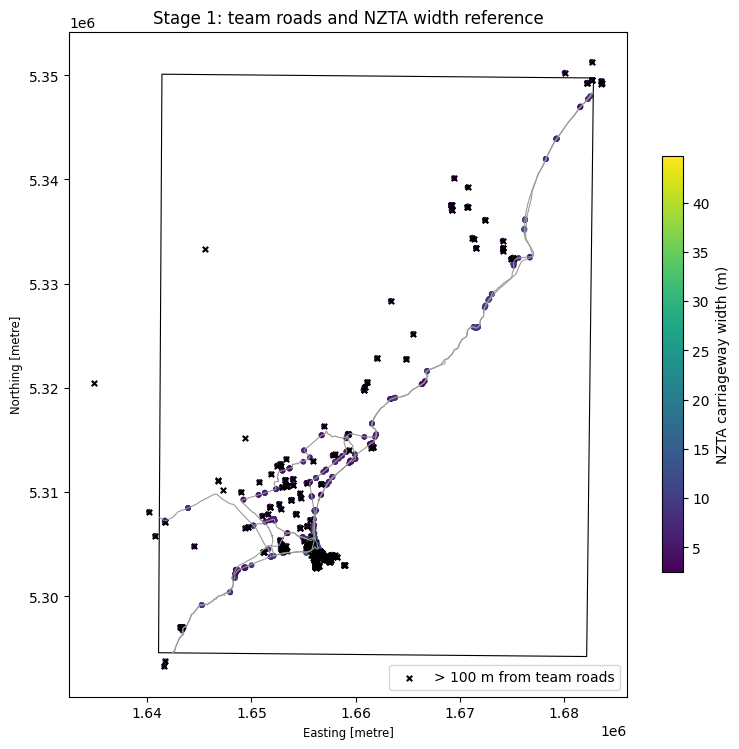

Stage 1 done. Saved: ['stage1_location_preview.csv', 'kai_route.gpkg', 'stage1_map.png', 'nzta_rca_aoi.gpkg']
Paste everything printed above back to Claude to continue to Stage 2 (lidar width).


In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))
gpd.GeoSeries([aoi_nztm], crs=CRS).boundary.plot(ax=ax, color="black", lw=0.8)
roads.plot(ax=ax, color="#999999", lw=0.8)
w = near[near["width_m"].notna()]
if len(w):
    w.plot(ax=ax, column="width_m", cmap="viridis", markersize=10, legend=True,
           legend_kwds={"label": "NZTA carriageway width (m)", "shrink": 0.6})
if (~matched).any():
    near[~matched].plot(ax=ax, color="black", marker="x", markersize=15, label=f"> {MATCH_MAX_M} m from team roads")
ax.set_title("Stage 1: team roads and NZTA width reference")
ax.set_aspect("equal"); ax.legend(loc="lower right")
fig.savefig(ROOT / "stage1_map.png", dpi=150, bbox_inches="tight")
plt.show()

print("Stage 1 done. Saved:", [p.name for p in ROOT.iterdir()])